In [2]:
import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf

import pickle 
from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.signal import argrelextrema

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Input, RepeatVector, TimeDistributed
from sklearn.preprocessing import MinMaxScaler

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

In [2]:
df = read_obj("Project_final")

In [3]:
df.index = pd.to_datetime(df.index)

In [4]:
df.head()

,b210_pt,b210_rt,b210_st,b210_fw,b081_1,b081_2,b081_raw_1,b081_raw_2,b081_rt_1,b081_rt_2,...,b002,b002_raw,b002_rt,b002_st,b002_fw,b084,b084_raw,b084_rt,b084_st,b084_fw
Date/Time,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,NaN,NaN,NaN,NaN,786964.343750,NaN,786964.343750,NaN,50.105000,50.397500,...,3563029.75,3563029.75,47.842500,44.3750,340.125000,4504438.50,4504438.50,48.477500,44.244999,288.012497
2022-01-01 01:00:00,NaN,NaN,NaN,NaN,786976.875000,NaN,786976.875000,NaN,50.069999,50.365001,...,3563077.25,3563077.25,47.677501,44.2350,341.325005,4504489.25,4504489.25,48.397499,44.124999,286.897499
2022-01-01 02:00:00,NaN,NaN,NaN,NaN,786990.031250,NaN,786990.031250,NaN,50.030001,50.337501,...,3563125.50,3563125.50,47.565000,44.2075,339.275002,4504540.50,4504540.50,48.372499,44.097499,286.294998
2022-01-01 03:00:00,NaN,NaN,NaN,NaN,787003.109375,NaN,787003.109375,NaN,50.009999,50.295000,...,3563173.25,3563173.25,47.532499,44.0850,340.424995,4504592.25,4504592.25,48.295000,43.964999,285.067505
2022-01-01 04:00:00,NaN,NaN,NaN,NaN,787016.265625,NaN,787016.265625,NaN,50.000000,50.300001,...,3563222.25,3563222.25,47.627501,44.1350,344.524994,4504644.25,4504644.25,48.344999,43.982499,285.160004


In [5]:
df['b081'] = df['b081_1'] + df['b081_2']
df['b081_raw'] = df['b081_raw_1'] + df['b081_raw_2']
df['b081_rt'] = df['b081_rt_1'] + df['b081_rt_2']
df['b081_st'] = df['b081_st_1'] + df['b081_st_2']
df['b081_fw'] = df['b081_fw_1'] + df['b081_fw_2']

df = df.drop(['b081_1', "b081_2", "b081_raw_1", "b081_raw_2", "b081_rt_1", "b081_rt_2", "b081_st_1", "b081_st_2", "b081_fw_1", "b081_fw_2"], axis = 1)

In [6]:
# Extract data with pt
filtered_columns = [col for col in df.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
subset_df = df[filtered_columns]["2022-04-01": "2022-12-31"]

In [7]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(subset_df)
scaled_df = pd.DataFrame(scaled_data, columns = subset_df.columns, index = subset_df.index)
scaled_df[scaled_df < -3] = None

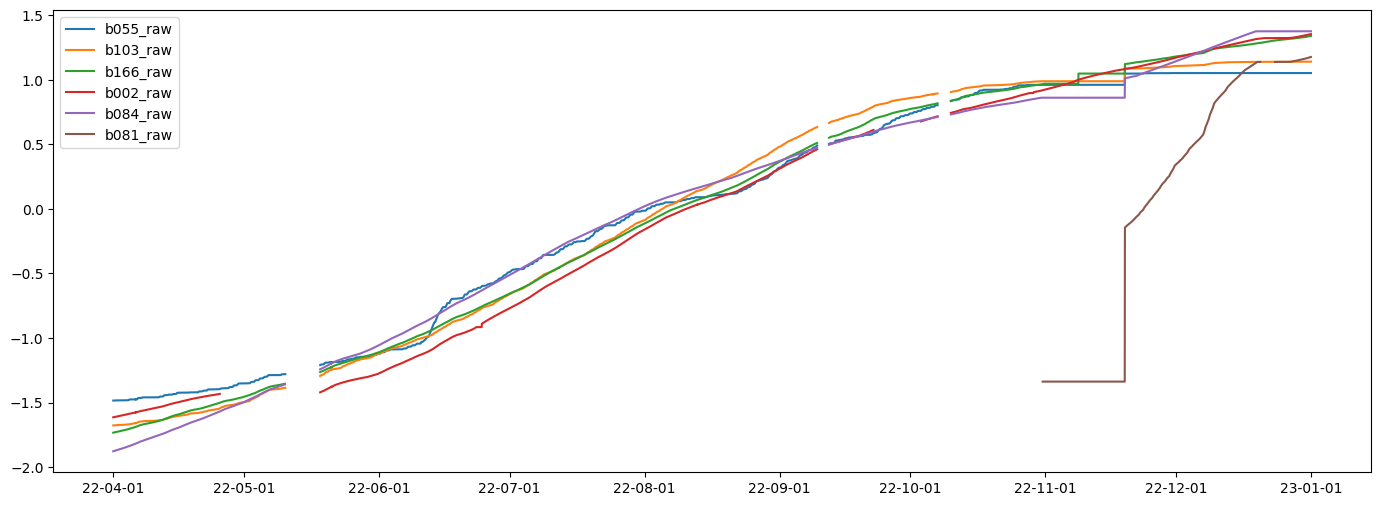

In [8]:
# Visualization
plt.figure(figsize = (17, 6))

for column in scaled_df.columns:
    plt.plot(scaled_df.index, scaled_df[column], label=column)

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

In [9]:
# Add another building (to compare pattern)

another = read_obj("project_CHW") # share only elec system
another.index = pd.to_datetime(another.index)
another = another.drop(['Date/Time'], axis = 1)

# add as group 
prefix = "_group1" 
another.columns = [col + prefix for col in another.columns]

prefix = "_group2" 
df.columns = [col + prefix for col in df.columns]

df_merge = pd.merge(df, another, left_index=True, right_index=True)

In [10]:
df_merge

,b210_pt_group2,b210_rt_group2,b210_st_group2,b210_fw_group2,b055_group2,b055_raw_group2,b055_rt_group2,b055_st_group2,b055_fw_group2,b103_group2,...,b116_pt_group1,b116_raw_group1,b116_rt_group1,b116_st_group1,b116_fw_group1,b064_pt_group1,b064_raw_group1,b064_rt_group1,b064_st_group1,b064_fw_group1
Date/Time,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,NaN,NaN,NaN,NaN,2543639.0,2543639.0,70.982498,81.222500,152.129997,376429.00,...,2745.454956,2745.454956,49.089999,44.592500,243.25,5032.895020,5032.895020,50.062500,44.335000,391.00
2022-01-01 01:00:00,NaN,NaN,NaN,NaN,2543639.0,2543639.0,71.085001,81.302502,152.242500,376437.00,...,2745.505005,2745.505005,49.022500,44.297501,236.00,5032.987549,5032.987549,49.912500,44.022500,389.25
2022-01-01 02:00:00,NaN,NaN,NaN,NaN,2543639.0,2543639.0,71.175001,81.392500,152.404999,376445.00,...,2745.550049,2745.550049,49.287500,44.240001,227.00,5033.084961,5033.084961,49.867500,43.972500,386.50
2022-01-01 03:00:00,NaN,NaN,NaN,NaN,2543639.0,2543639.0,71.265001,81.464998,152.325001,376453.25,...,2745.597595,2745.597595,49.257500,44.359999,236.75,5033.177490,5033.177490,50.059999,44.092501,368.75
2022-01-01 04:00:00,NaN,NaN,NaN,NaN,2543639.0,2543639.0,71.360001,81.567499,152.309998,376462.00,...,2745.644897,2745.644897,49.062501,44.445000,248.00,5033.269897,5033.269897,50.045001,44.180000,365.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-05-03 19:00:00,124420.0,44.095000,43.462728,147.171818,2621294.0,2621294.0,331.075006,45.677500,151.152504,450451.50,...,3348.525024,3348.575073,47.997500,44.142500,294.75,5944.715088,5944.779907,51.459999,43.884999,192.25
2023-05-03 20:00:00,124430.0,44.364285,43.733751,111.796249,2621294.0,2621294.0,485.562499,45.802500,150.597500,450456.00,...,3348.575073,3348.617493,48.267500,44.860000,295.25,5944.779907,5944.839966,51.690001,44.347500,195.50
2023-05-03 21:00:00,124430.0,47.491428,47.986667,36.345000,2621294.0,2621294.0,648.480011,46.090000,150.487499,450460.00,...,3348.617493,3348.664917,48.380000,44.725000,295.00,5944.839966,5944.897461,51.639999,44.627501,190.00


In [11]:
df_merge.index = df_merge.index.strftime('%Y-%m-%d %H:%M:%S')

In [12]:
# Extract data with pt
filtered_columns = [col for col in df_merge.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
subset_df_merge = df_merge[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [13]:
subset_df_merge.index = pd.to_datetime(subset_df_merge.index)

In [14]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(subset_df_merge)
scaled_df = pd.DataFrame(scaled_data, columns=subset_df_merge.columns, index=subset_df_merge.index)
scaled_df[scaled_df < -3] = None
scaled_df[scaled_df > 7] = None

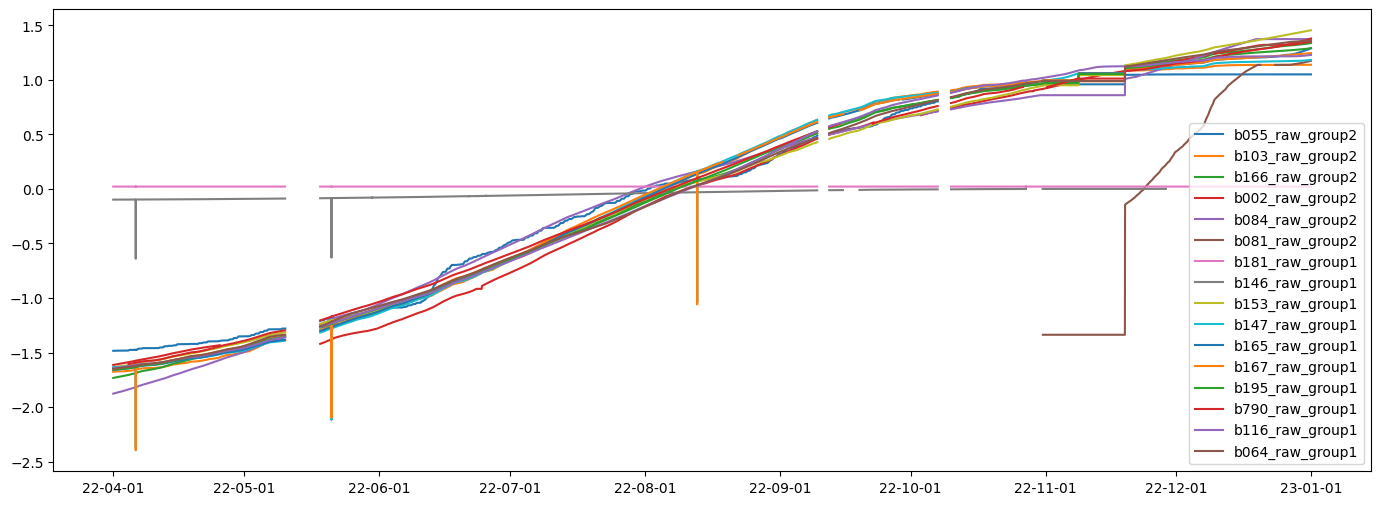

In [15]:
# Visualization
plt.figure(figsize=(17, 6))

for column in scaled_df.columns:
    plt.plot(scaled_df.index, scaled_df[column], label=column)

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

In [16]:
group_names = scaled_df.columns.str.split('_').str[-1].unique()

['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2', 'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2']


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55809/3763846801.py:9: UserWarning: 
The palette list has fewer values (1) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(data = scaled_df[group_columns], dashes = False, markers = True, palette = [palette[i]], alpha = 0.7)


['b181_raw_group1', 'b146_raw_group1', 'b153_raw_group1', 'b147_raw_group1', 'b165_raw_group1', 'b167_raw_group1', 'b195_raw_group1', 'b790_raw_group1', 'b116_raw_group1', 'b064_raw_group1']


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55809/3763846801.py:9: UserWarning: 
The palette list has fewer values (1) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(data = scaled_df[group_columns], dashes = False, markers = True, palette = [palette[i]], alpha = 0.7)


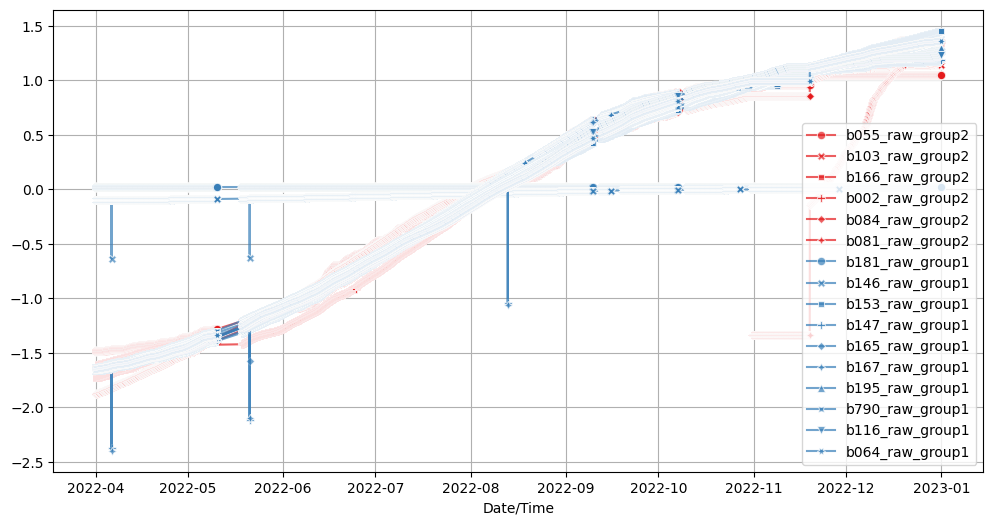

In [17]:
# var_group1과 var_group2를 선택하여 그래프에 그리기
plt.figure(figsize=(12, 6))

palette = sns.color_palette("Set1", len(group_names))  # Set1 팔레트 사용

for i, group in enumerate(group_names):
    group_columns = [col for col in scaled_df.columns if group in col]
    print(group_columns)
    sns.lineplot(data = scaled_df[group_columns], dashes = False, markers = True, palette = [palette[i]], alpha = 0.7)

plt.legend()
plt.grid(True)

plt.show()

### EDA Group 1 data

In [3]:
### Visualization 2020 to 2023

df1 = read_obj("Project_final_20_23")

In [4]:
# Extract data with pt
filtered_columns = [col for col in df1.columns if ("raw" in col or "pt" in col)]

# 선택한 변수를 새로운 데이터 프레임으로 추출
df1 = df1[filtered_columns]

In [5]:
df1 = df1.diff()

In [6]:
df1['b081_raw'] = df1['b081_raw_1'] + df1['b081_raw_2']
df1 = df1.drop(['b081_raw_2', 'b081_raw_1'], axis = 1)

In [7]:
df1.columns

Index(['b210_pt', 'b055_raw', 'b103_raw', 'b166_raw', 'b002_raw', 'b084_raw',
       'b081_raw'],
      dtype='object')

In [8]:
# save_obj(df1, "Project_final_pt_20_23")
# df1.to_csv("Project_final_pt_20_23.csv")

In [9]:
df1[df1 > 1000] = None
df1[df1 < -1000] = None
df1.index = pd.to_datetime(df1.index)

In [10]:
df1.to_csv("./CSV data/daytime_nighttime.csv")

In [11]:
# subdata with 10am/pm to 2am/pm
# 시간대 설정
morning_range = pd.to_datetime(['10:00:00', '14:00:00']).time
evening_range = pd.to_datetime(['22:00:00', '02:00:00']).time

# 오전 10시부터 오후 2시까지와 오후 10시부터 오전 2시까지 데이터 추출
morning_data = df1.between_time('10:00:00', '14:00:00')
evening_data = df1.between_time('22:00:00', '02:00:00')
combined_data = pd.concat([morning_data, evening_data])

combined_data = combined_data.sort_index()

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/642812305.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  morning_range = pd.to_datetime(['10:00:00', '14:00:00']).time
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/642812305.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  evening_range = pd.to_datetime(['22:00:00', '02:00:00']).time


In [12]:
def day_night_visualization(df):
    # Daytime: AM 6 ~ 18
    daytime = df.between_time('06:00', '18:00')
    nighttime = df.drop(daytime.index)
    
    # 그래프 생성
    plt.figure(figsize=(15, 6))
    plt.plot(daytime.index, daytime['b166_raw'], label='Daytime', marker='o', linestyle='none')
    plt.plot(nighttime.index, nighttime['b166_raw'], label='Nighttime', marker='o', linestyle='none')
    
    # 그래프 스타일 설정
    plt.title('Day-Night b166 Visualization')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# 함수 호출
# day_night_visualization(df1["2020-07-01 06:00:00":"2020-07-05 18:00:00"])

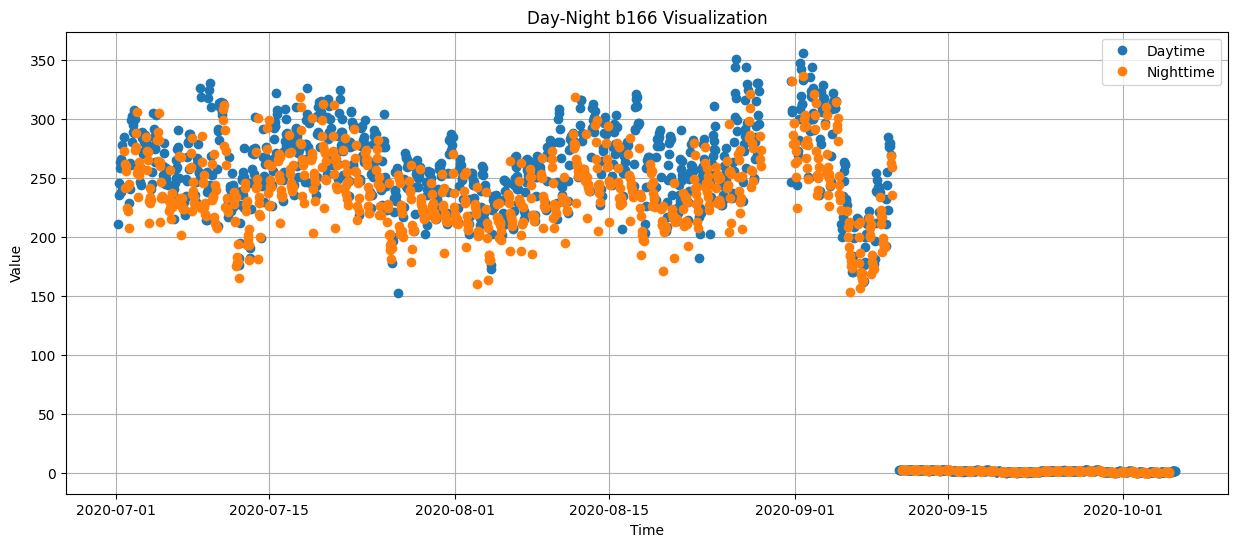

In [13]:
# 함수 호출
# df1[df1['b002_raw'] > 400] = None
day_night_visualization(df1["2020-07-01 06:00:00":"2020-10-05 18:00:00"])

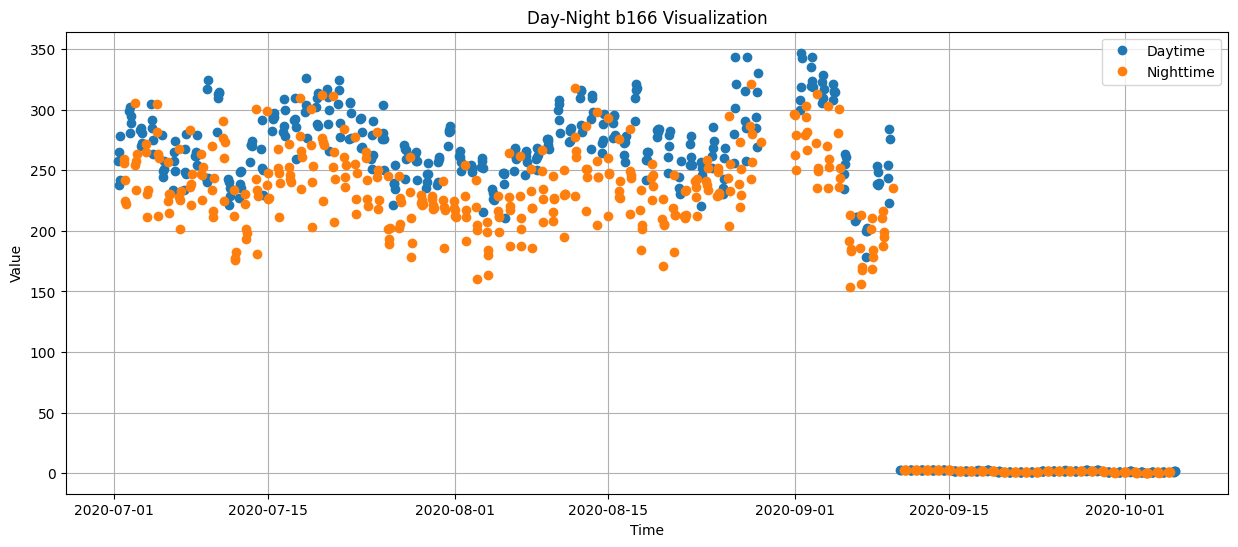

In [14]:
combined_data[combined_data['b002_raw'] > 400] = None
day_night_visualization(combined_data["2020-07-01 06:00:00":"2020-10-05 18:00:00"])

                       b210_pt  b055_raw  b103_raw    b166_raw  b002_raw  \
Date/Time                                                                  
2020-07-01 19:00:00   9.411765    196.25  0.132385  273.000000     56.75   
2020-07-01 20:00:00   9.411765    193.25  0.132568  261.250000     53.50   
2020-07-01 21:00:00   9.411765    190.50  0.114929  241.500000     50.25   
2020-07-01 22:00:00   9.411765    186.75  0.080078  259.500000     49.50   
2020-07-01 23:00:00   9.411765    185.25  0.070007  256.000000     48.75   
2020-07-02 00:00:00   9.411765    183.00  0.079895  224.500000     47.50   
2020-07-02 01:00:00   9.411765    181.00  0.080078  242.000000     47.25   
2020-07-02 02:00:00   4.545455    178.75  0.070068  222.250000     47.00   
2020-07-02 03:00:00   4.545455    177.25  0.079834  243.000000     45.25   
2020-07-02 04:00:00   4.545455    176.50  0.070068  207.500000     44.25   
2020-07-02 05:00:00   4.545455    178.00  0.080078  245.000000     44.25   
2020-07-02 1

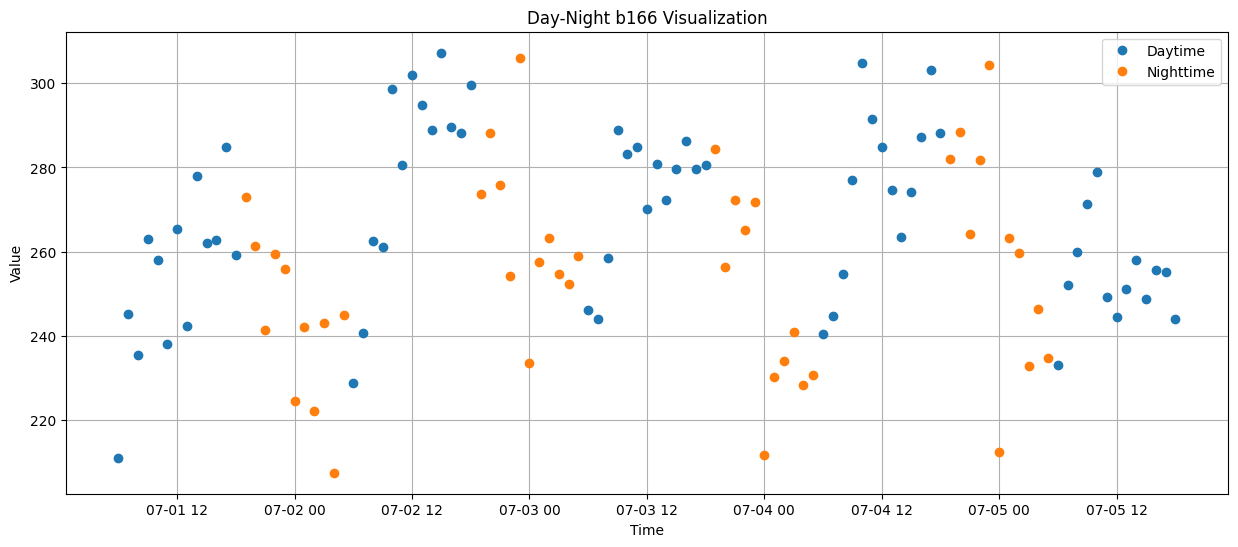

In [13]:
def day_night_visualization(df):
    # Daytime: AM 6 ~ 18
    daytime = df.between_time('06:00', '18:00')
    nighttime = df.drop(daytime.index)
    print(nighttime)
    
    # 그래프 생성
    plt.figure(figsize=(15, 6))
    plt.plot(daytime.index, daytime['b166_raw'], label='Daytime', marker='o', linestyle='none')
    plt.plot(nighttime.index, nighttime['b166_raw'], label='Nighttime', marker='o', linestyle='none')
    
    # 그래프 스타일 설정
    plt.title('Day-Night b166 Visualization')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# 함수 호출
day_night_visualization(df1["2020-07-01 06:00:00":"2020-07-05 18:00:00"])

                       b210_pt  b055_raw  b103_raw  b166_raw  b002_raw  \
Date/Time                                                                
2020-06-01 06:00:00   3.333333    151.00  0.132568      0.00     52.50   
2020-06-01 07:00:00   8.571429    152.50  0.197510      0.00     57.50   
2020-06-01 08:00:00   8.571429    162.25  0.152466       NaN     59.50   
2020-06-01 09:00:00   8.571429    176.25  0.147583       NaN     60.50   
2020-06-01 10:00:00   8.571429    186.75  0.137390      0.00     65.00   
...                        ...       ...       ...       ...       ...   
2020-10-29 14:00:00  10.000000    181.75  0.202515    200.75     64.75   
2020-10-29 15:00:00  10.000000    163.25  0.202454    191.25     63.50   
2020-10-29 16:00:00  10.000000    142.25  0.175049    181.75     63.00   
2020-10-29 17:00:00  10.000000    130.00  0.152466    175.75     57.75   
2020-10-29 18:00:00  10.000000    104.75  0.142517    145.75     53.00   

                     b084_raw  b081_r

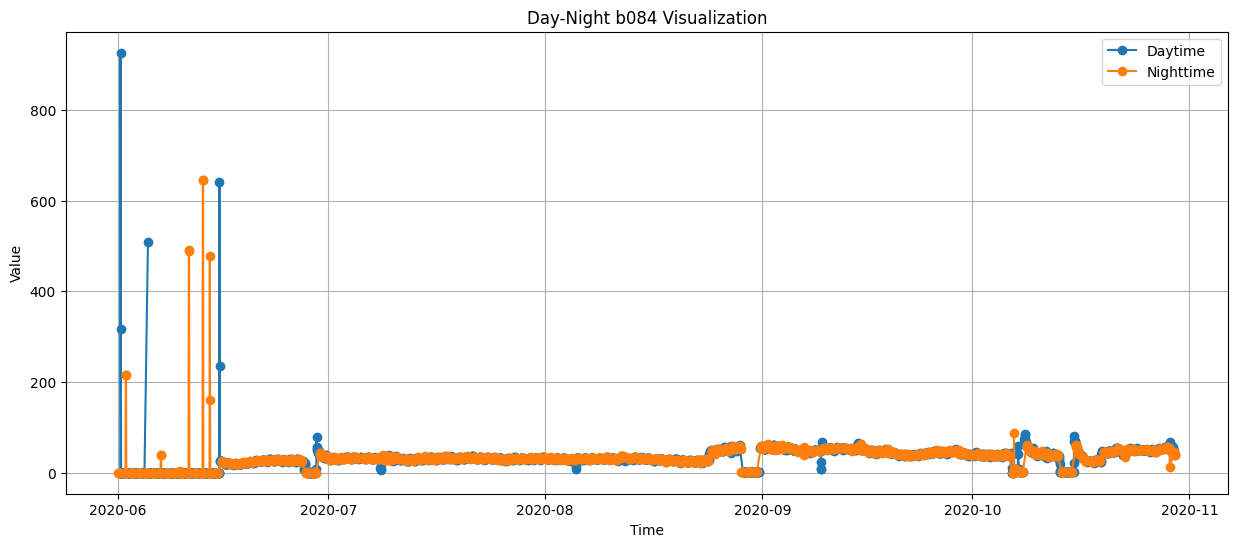

In [16]:
# Visualization (Night, Daytime)
# remove point more than 100 and less than -100

def day_night_visualization(df):
    # Daytime: AM 6 ~ 18
    daytime = df.between_time('06:00', '18:00')
    nighttime = df.drop(daytime.index)
    print(daytime)
    
    # 그래프 생성
    plt.figure(figsize=(15, 6))
    plt.plot(daytime.index, daytime['b084_raw'], label='Daytime', marker='o')
    plt.plot(nighttime.index, nighttime['b084_raw'], label='Nighttime', marker='o')
    
    # 그래프 스타일 설정
    plt.title('Day-Night b084 Visualization')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# 함수 호출
day_night_visualization(df1["2020-06-01 00:00:00":"2020-10-30 00:00:00"])

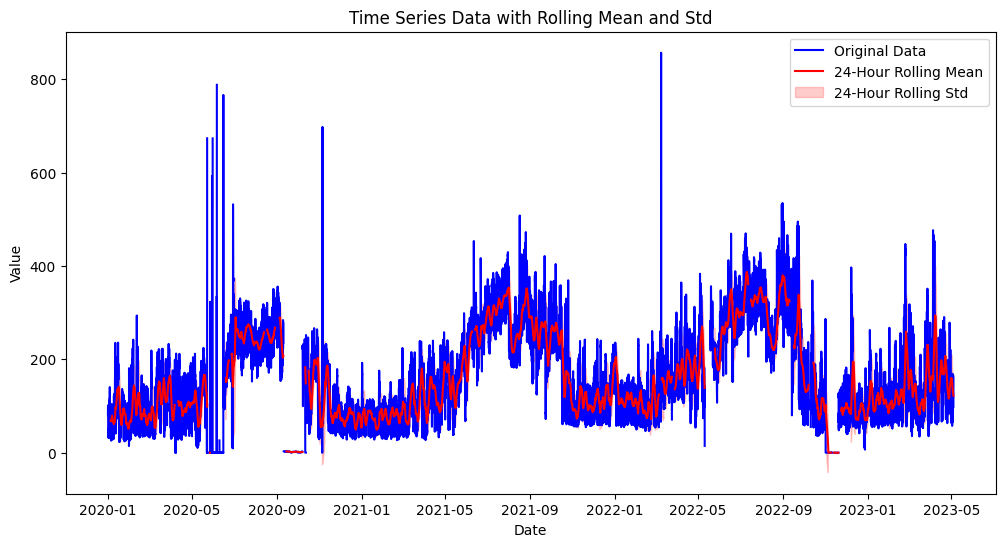

In [17]:
### Extract drift area

# 이동평균 및 이동표준편차 계산
window_size = 24 * 4 # 이동평균과 이동표준편차를 계산할 윈도우 크기
df1['rolling_mean'] = df1['b166_raw'].rolling(window=window_size).mean()
df1['rolling_std'] = df1['b166_raw'].rolling(window=window_size).std()

# 시각화
plt.figure(figsize=(12, 6))
plt.plot(df1.index, df1['b166_raw'], label='Original Data', color='blue')
plt.plot(df1.index, df1['rolling_mean'], label=f'{window_size//4}-Hour Rolling Mean', color='red')
plt.fill_between(df1.index, df1['rolling_mean'] - df1['rolling_std'], df1['rolling_mean'] + df1['rolling_std'], color='red', alpha=0.2, label=f'{window_size//4}-Hour Rolling Std')
plt.title('Time Series Data with Rolling Mean and Std')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.show()

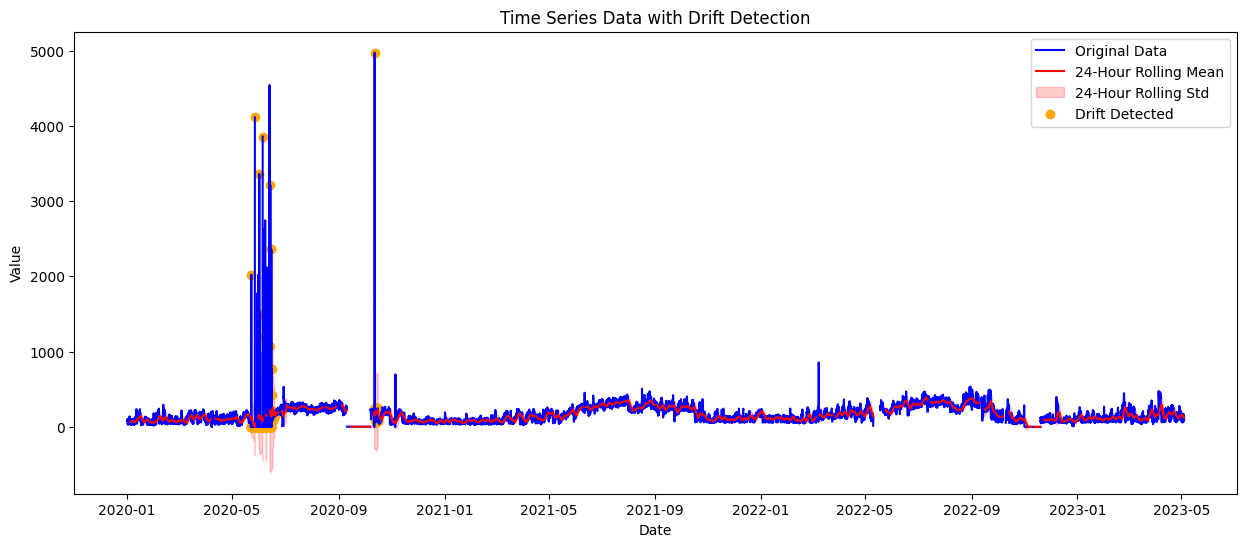

In [57]:
### visualization with threshold 

# threshold 설정
threshold = 100.0  # 임계값 설정

# Drift가 발생하는 부분 식별 with range
std_threshold = df1['rolling_std'].mean() + 2 * df1['rolling_std'].std()
drift_mask = df1['rolling_std'] > std_threshold

# 시각화
plt.figure(figsize=(15, 6))
plt.plot(df1.index, df1['b166_raw'], label='Original Data', color='blue')
plt.plot(df1.index, df1['rolling_mean'], label=f'{window_size//4}-Hour Rolling Mean', color='red')
plt.fill_between(df1.index, df1['rolling_mean'] - df1['rolling_std'], df1['rolling_mean'] + df1['rolling_std'], color='red', alpha=0.2, label=f'{window_size//4}-Hour Rolling Std')
plt.scatter(df1.index[drift_mask], df1['b166_raw'][drift_mask], color='orange', label='Drift Detected')
plt.title('Time Series Data with Drift Detection')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.show()

In [58]:
# Get shift index
drift_points = df1.index[drift_mask]
drift_points

DatetimeIndex(['2020-05-23 03:00:00', '2020-05-23 04:00:00',
               '2020-05-23 05:00:00', '2020-05-23 06:00:00',
               '2020-05-23 07:00:00', '2020-05-23 08:00:00',
               '2020-05-23 09:00:00', '2020-05-23 10:00:00',
               '2020-05-23 11:00:00', '2020-05-23 12:00:00',
               ...
               '2020-10-15 23:00:00', '2020-10-16 00:00:00',
               '2020-10-16 01:00:00', '2020-10-16 02:00:00',
               '2020-10-16 03:00:00', '2020-10-16 04:00:00',
               '2020-10-16 05:00:00', '2020-10-16 06:00:00',
               '2020-10-16 07:00:00', '2020-10-16 08:00:00'],
              dtype='datetime64[ns]', name='Date/Time', length=456, freq=None)

In [95]:
df = df1
df['Date'] = df.index

In [96]:
df1.columns

Index(['b210_pt', 'b055_raw', 'b103_raw', 'b166_raw', 'b002_raw', 'b084_raw',
       'b081_raw', 'Date_without_year', 'Date'],
      dtype='object')

In [15]:
# df1[['b103_raw', 'b166_raw', 'b084_raw', 'b081_raw']].plot()

In [97]:
temp_df = df1.drop(['Date', "Date_without_year"], axis = 1)

In [98]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(temp_df)
temp_df = pd.DataFrame(scaled_data, columns = temp_df.columns, index = temp_df.index)

In [99]:
temp_df['Date'] = df1["Date"]

### Detect convex for one-day

In [16]:
df1.head()

,b210_pt,b055_raw,b103_raw,b166_raw,b002_raw,b084_raw,b081_raw
Date/Time,,,,,,,
2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 01:00:00,NaN,37.25,0.5,82.25,18.00,28.25,NaN
2020-01-01 02:00:00,NaN,32.50,0.5,92.25,15.75,26.75,NaN
2020-01-01 03:00:00,NaN,28.25,0.0,89.75,16.00,26.75,NaN
2020-01-01 04:00:00,NaN,32.25,0.0,84.00,15.75,26.25,NaN


In [14]:
def find_extremes_in_window(df, var, window_size):
    # 시계열 데이터를 주어진 윈도우 크기로 평균을 구함
    rolling_avg = df[var].rolling(window = window_size, center = True).mean()

    # 최솟값과 최댓값을 가지는 인덱스 찾기
    min_index = rolling_avg.idxmin()
    max_index = rolling_avg.idxmax()

    # 최솟값과 최댓값의 앞뒤 구간 찾기 (예: 3시간)
    start_time_min = min_index - pd.Timedelta(hours = window_size)
    end_time_min = min_index + pd.Timedelta(hours = window_size)

    print(f"Lowest point: {min_index}, Window: {start_time_min} to {end_time_min}")

    start_time_max = max_index - pd.Timedelta(hours = window_size)
    end_time_max = max_index + pd.Timedelta(hours = window_size)

    print(f"Highest point: {max_index}, Window: {start_time_max} to {end_time_max}")

    # 그래프로 표시
    plt.figure(figsize = (10, 6))
    df[var].plot(label = 'Original Time Series')
    rolling_avg.plot(label = 'Rolling Average', linestyle = '--', color = 'red')
    plt.scatter(min_index, df[var][min_index], color = 'blue', label = 'Lowest Point')
    plt.scatter(max_index, df[var][max_index], color = 'green', label = 'Highest Point')

    plt.title('Time Series with Extremes')
    plt.show()

Lowest point: 2020-08-08 01:00:00, Window: 2020-08-07 01:00:00 to 2020-08-09 01:00:00
Highest point: 2022-07-07 01:00:00, Window: 2022-07-06 01:00:00 to 2022-07-08 01:00:00


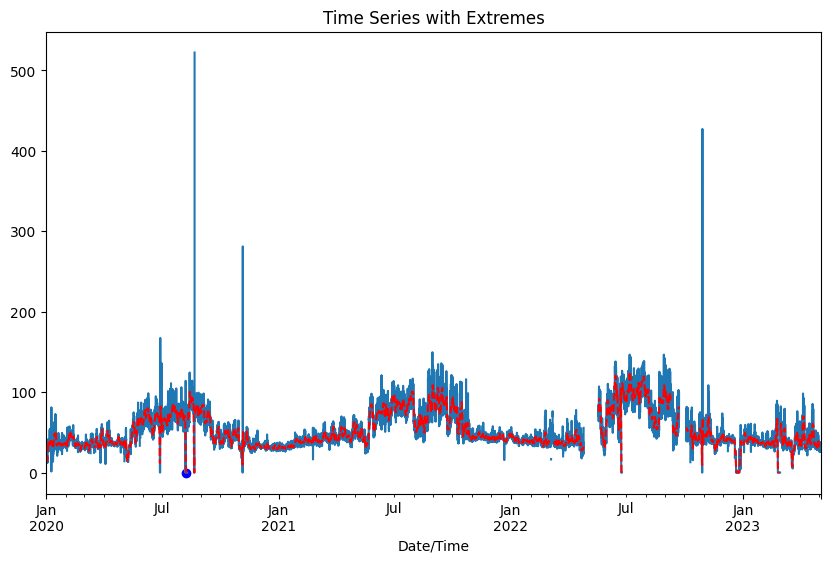

In [15]:
# sliding window 크기 설정 (예: 24시간)
window_size = 24

# 최솟값과 최댓값 찾기
find_extremes_in_window(df1, 'b002_raw', window_size)

<Axes: xlabel='Date/Time'>

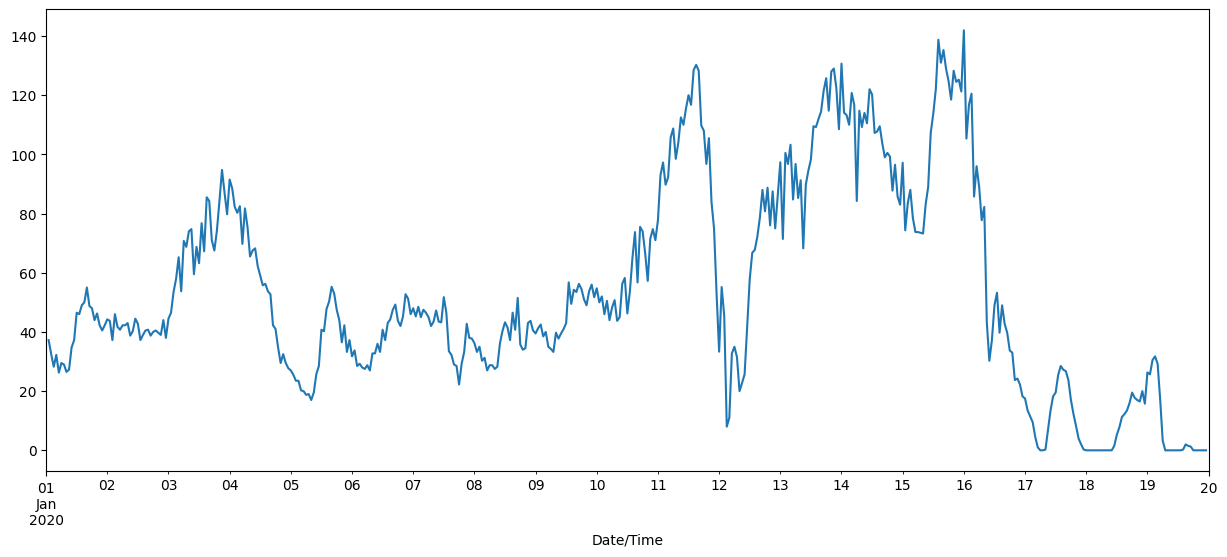

In [22]:
plt.figure(figsize = (15, 6))
df1['b055_raw']["2020-01-01 00:00:00": "2020-01-20 00:00:00"].plot()

In [18]:
df1 = df1.fillna(method = "ffill")
df1 = df1.fillna(method = "bfill")
df1 = df1.set_index(pd.to_datetime(df1.index))

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_20765/3118476007.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1 = df1.fillna(method = "ffill")
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_20765/3118476007.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1 = df1.fillna(method = "bfill")


In [47]:
df1.index.date

array([datetime.date(2020, 1, 1), datetime.date(2020, 1, 1),
       datetime.date(2020, 1, 1), ..., datetime.date(2023, 5, 3),
       datetime.date(2023, 5, 3), datetime.date(2023, 5, 3)], dtype=object)

Lowest Point on 2020-01-01: 2020-01-01 22:00:00, Window: 2020-01-01 19:00:00 to 2020-01-02 01:00:00
Lowest Point on 2020-01-02: 2020-01-02 12:00:00, Window: 2020-01-02 09:00:00 to 2020-01-02 15:00:00
Lowest Point on 2020-01-03: 2020-01-03 02:00:00, Window: 2020-01-02 23:00:00 to 2020-01-03 05:00:00
Lowest Point on 2020-01-04: 2020-01-04 17:00:00, Window: 2020-01-04 14:00:00 to 2020-01-04 20:00:00
Lowest Point on 2020-01-05: 2020-01-05 19:00:00, Window: 2020-01-05 16:00:00 to 2020-01-05 22:00:00
Lowest Point on 2020-01-06: 2020-01-06 21:00:00, Window: 2020-01-06 18:00:00 to 2020-01-07 00:00:00
Lowest Point on 2020-01-07: 2020-01-07 03:00:00, Window: 2020-01-07 00:00:00 to 2020-01-07 06:00:00
Lowest Point on 2020-01-08: 2020-01-08 22:00:00, Window: 2020-01-08 19:00:00 to 2020-01-09 01:00:00
Lowest Point on 2020-01-09: 2020-01-09 06:00:00, Window: 2020-01-09 03:00:00 to 2020-01-09 09:00:00
Lowest Point on 2020-01-10: 2020-01-10 05:00:00, Window: 2020-01-10 02:00:00 to 2020-01-10 08:00:00


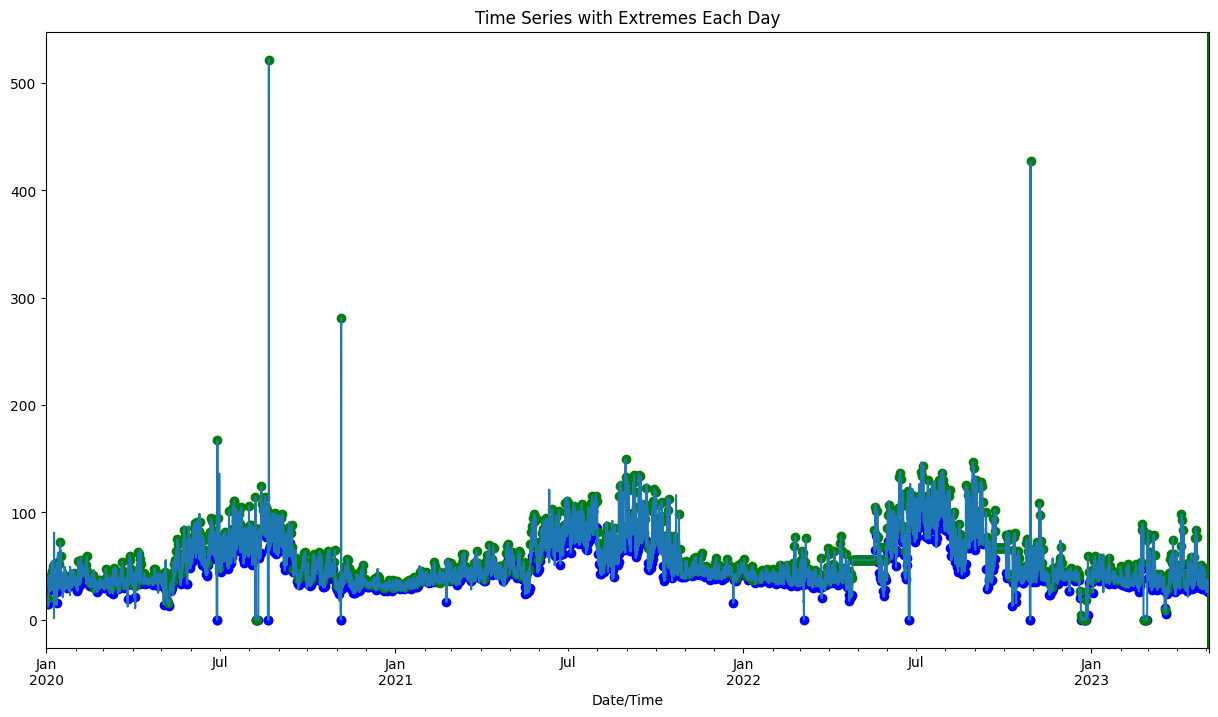

In [19]:
def find_extremes_each_day(df, var, window_size):
    # 날짜별로 최솟값과 최댓값을 저장할 리스트
    min_points = []
    max_points = []

    # 날짜별로 구간을 찾음
    for day, data in df.groupby(df.index.date):
        rolling_avg = data[var].rolling(window=window_size, center=True).mean()

        # 최솟값과 최댓값을 가지는 인덱스 찾기
        min_index = rolling_avg.idxmin()
        max_index = rolling_avg.idxmax()

        min_points.append((day, min_index, data[var][min_index]))
        max_points.append((day, max_index, data[var][max_index]))

    # 찾은 구간을 출력
    for point_type, points in zip(['Lowest Point', 'Highest Point'], [min_points, max_points]):
        for day, index, value in points:
            start_time = index - pd.Timedelta(hours=3)
            end_time = index + pd.Timedelta(hours=3)
            print(f"{point_type} on {day}: {index}, Window: {start_time} to {end_time}")

    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    df[var].plot(label='Original Time Series')
    
    for points, color in zip([min_points, max_points], ['blue', 'green']):
        for day, index, value in points:
            plt.scatter(index, value, color=color, label=f'{day} - {point_type}')
            plt.axvspan(start_time, end_time, alpha=0.2, color=color)  # 윈도우 영역 배경색 설정


    plt.title('Time Series with Extremes Each Day')
    plt.show()

# sliding window 크기 설정 (예: 24시간)
window_size = 3

# 최솟값과 최댓값 찾기 및 그래프로 표시
find_extremes_each_day(df1, 'b002_raw', window_size)

In [29]:
df2 = df1["2020-01-01 00:00:00": "2021-10-07 00:00:00"]
# df2 = df2.set_index(pd.to_datetime(df2.index))

In [75]:
# 구간 표시 
def find_extremes_each_day(df, window_size):
    # 날짜별로 최솟값과 최댓값을 저장할 리스트
    min_points = []
    max_points = []

    # 날짜별로 구간을 찾음
    for day, data in df.groupby(df.index.date):
        rolling_avg = data['b055_raw'].rolling(window=window_size, center=True).mean()
        print(rolling_avg)
        # 최솟값과 최댓값을 가지는 인덱스 찾기
        min_index = rolling_avg.idxmin()
        max_index = rolling_avg.idxmax()

        min_points.append((day, min_index, data['b055_raw'][min_index]))
        max_points.append((day, max_index, data['b055_raw'][max_index]))

    # 찾은 구간을 출력
    for point_type, points in zip(['Lowest Point', 'Highest Point'], [min_points, max_points]):
        for day, index, value in points:
            start_time = index - pd.Timedelta(hours=3)
            end_time = index + pd.Timedelta(hours=3)
            print(f"{point_type} on {day}: {index}, Window: {start_time} to {end_time}")

    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    df['b055_raw'].plot(label='Original Time Series')

    for points, color in zip([min_points, max_points], ['blue', 'green']):
        for day, index, value in points:
            plt.scatter(index, value, color=color, label=f'{day} - {point_type}')
            plt.fill_between(df.index, df['b055_raw'], where=((df.index >= start_time) & (df.index <= end_time)), color=color, alpha=0.2)

    plt.title('Time Series with Extremes Each Day')
    plt.show()

# sliding window 크기 설정 (예: 24시간)
window_size = 1

# 최솟값과 최댓값 찾기 및 그래프로 표시
# find_extremes_each_day(df1, window_size)

In [24]:
df2 = df1["2020-01-01 00:00:00": "2020-01-12 23:00:00"]
# df2 = df2.drop(['rolling_mean', 'rolling_std'], axis = 1)
df2 = df2.fillna(method = "ffill")
df2 = df2.fillna(method = "bfill")
df2.dtypes
df2 = df2.reset_index()
df2 = df2.set_index(pd.to_datetime(df2['Date/Time']))
df2 = df2.drop(['Date/Time'], axis = 1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/1909240612.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df2 = df2.fillna(method = "ffill")
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/1909240612.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df2 = df2.fillna(method = "bfill")


In [68]:
def find_extremes_each_day2(df, window_size):
    # 날짜별로 최솟값과 최댓값을 저장할 리스트
    min_points = []
    max_points = []

    # 날짜별로 구간을 찾음
    for day, data in df.groupby(df.index.date):
        rolling_avg = data['b055_raw'].rolling(window=window_size, center=True).mean()
        print(rolling_avg)
        # 최솟값과 최댓값을 가지는 인덱스 찾기
        min_index = rolling_avg.idxmin()
        max_index = rolling_avg.idxmax()

        min_points.append((day, min_index, data['b055_raw'][min_index]))
        max_points.append((day, max_index, data['b055_raw'][max_index]))

    # 찾은 구간을 출력
    for point_type, points in zip(['Lowest Point', 'Highest Point'], [min_points, max_points]):
        for day, index, value in points:
            start_time = index - pd.Timedelta(hours=3)
            end_time = index + pd.Timedelta(hours=3)
            print(f"{point_type} on {day}: {index}, Window: {start_time} to {end_time}")

    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    df['b055_raw'].plot(label='Original Time Series')

    for points, color in zip([min_points, max_points], ['blue', 'green']):
        for day, index, value in points:
            plt.scatter(index, value, color=color, label=f'{day} - {point_type}')
            plt.fill_between(df.index, df['b055_raw'], where=((df.index >= start_time) & (df.index <= end_time)), color=color, alpha=0.2)

    plt.title('Time Series with Extremes Each Day')
    plt.show()

Date/Time
2020-01-01 00:00:00    37.25
2020-01-01 01:00:00    37.25
2020-01-01 02:00:00    32.50
2020-01-01 03:00:00    28.25
2020-01-01 04:00:00    32.25
2020-01-01 05:00:00    26.25
2020-01-01 06:00:00    29.50
2020-01-01 07:00:00    29.00
2020-01-01 08:00:00    26.50
2020-01-01 09:00:00    27.25
2020-01-01 10:00:00    34.75
2020-01-01 11:00:00    37.25
2020-01-01 12:00:00    46.50
2020-01-01 13:00:00    46.00
2020-01-01 14:00:00    49.00
2020-01-01 15:00:00    50.00
2020-01-01 16:00:00    55.00
2020-01-01 17:00:00    48.75
2020-01-01 18:00:00    48.00
2020-01-01 19:00:00    44.00
2020-01-01 20:00:00    46.25
2020-01-01 21:00:00    42.25
2020-01-01 22:00:00    40.50
2020-01-01 23:00:00    42.25
Name: b055_raw, dtype: float64
Date/Time
2020-01-02 00:00:00    44.25
2020-01-02 01:00:00    43.75
2020-01-02 02:00:00    37.25
2020-01-02 03:00:00    46.00
2020-01-02 04:00:00    41.75
2020-01-02 05:00:00    40.75
2020-01-02 06:00:00    42.25
2020-01-02 07:00:00    42.25
2020-01-02 08:00:00  

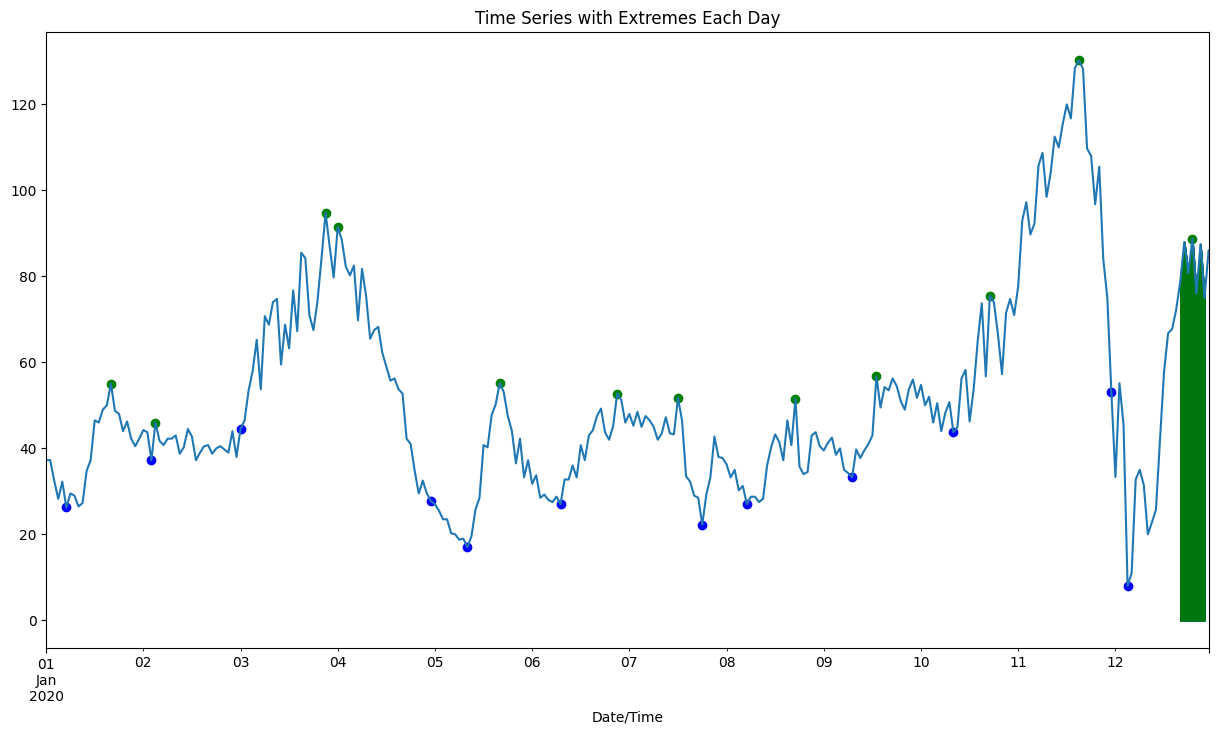

In [76]:
find_extremes_each_day(df2, window_size)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_77400/2998113168.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['smoothed_trend'] = np.nan


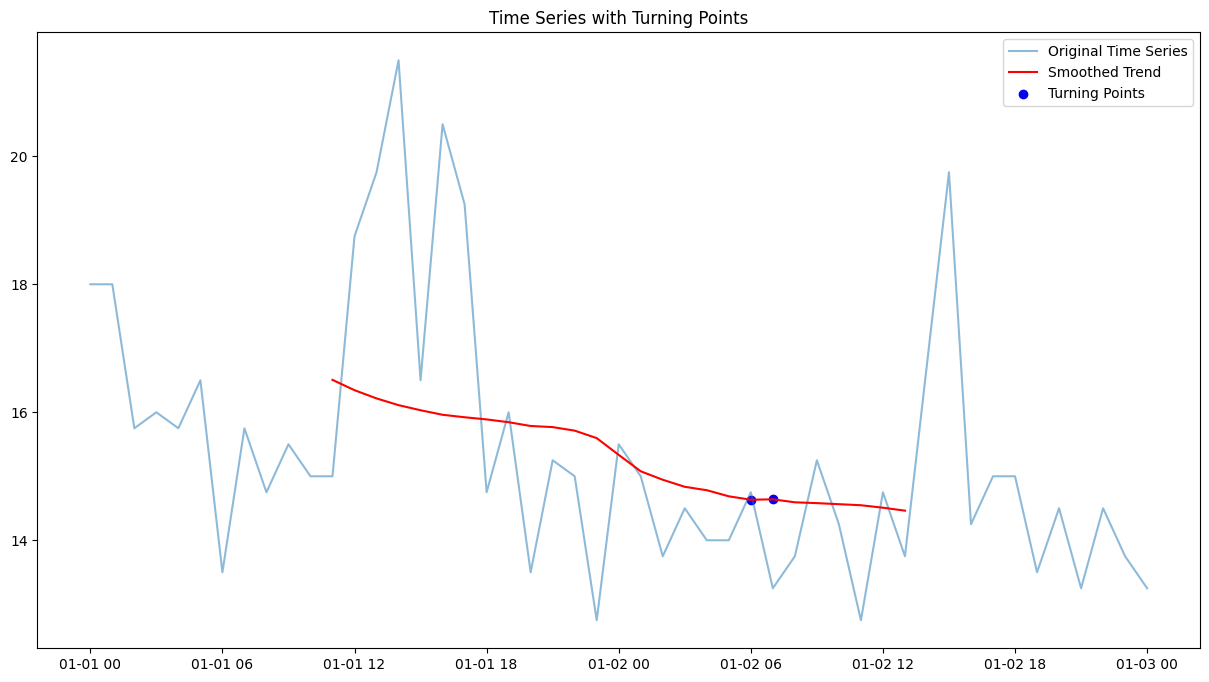

                     value  turning_point
2023-01-01 00:00:00      0              0
2023-01-01 01:00:00      1              0
2023-01-01 02:00:00      2              0
2023-01-01 03:00:00      3              0
2023-01-01 04:00:00      4              0
...                    ...            ...
2023-01-09 20:00:00    212              0
2023-01-09 21:00:00    213              0
2023-01-09 22:00:00    214              0
2023-01-09 23:00:00    215              0
2023-01-10 00:00:00    216              0

[217 rows x 2 columns]


In [57]:
from scipy.signal import savgol_filter
from statsmodels.tsa.seasonal import seasonal_decompose

def find_turning_points(df, window_size, polyorder):
    # 시계열 분해를 통해 trend 추출
    result = seasonal_decompose(df['b002_raw'], model='additive', period = 23)  # 주기성이 24인 경우 (하루 주기)

    # trend에 대해 데이터 스무딩 (Savitzky-Golay 필터 사용)
    smoothed_trend = savgol_filter(result.trend.dropna(), window_size, polyorder)

    # Align smoothed trend with the original time series by using interpolation
    smoothed_trend = pd.Series(smoothed_trend, index=result.trend.dropna().index)
    smoothed_trend = smoothed_trend.reindex(df.index, method='nearest')

    # Ensure both series have the same index
    df['smoothed_trend'] = np.nan
    df.loc[result.trend.dropna().index, 'smoothed_trend'] = smoothed_trend

    # Find turning points based on conditions
    turning_points = np.where(
        (df['smoothed_trend'].shift(-1) > df['smoothed_trend']) & (df['smoothed_trend'].shift(1) > df['smoothed_trend']) |
        (df['smoothed_trend'].shift(-1) < df['smoothed_trend']) & (df['smoothed_trend'].shift(1) < df['smoothed_trend'])
    )[0]
    
    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    plt.plot(df.index, df['b002_raw'], label='Original Time Series', alpha=0.5)
    plt.plot(df.index, df['smoothed_trend'], label='Smoothed Trend', color='red')
    plt.scatter(df.index[turning_points], df['smoothed_trend'].iloc[turning_points], color='blue', label='Turning Points')

    plt.title('Time Series with Turning Points')
    plt.legend()
    plt.show()

    return turning_points

# smoothing을 위한 window size 및 polynomial order 설정
window_size = 6
polyorder = 2

# 변곡점 찾기 및 그래프로 표시
turning_points = find_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], window_size, polyorder)

# 변곡점 정보가 추가된 데이터프레임 출력
print(df)


In [ ]:
from statsmodels.tsa.seasonal import STL

# STL 분해 수행
stl = STL(df1['b002_raw'], seasonal=13)  # seasonal 주기를 조절할 수 있습니다.
result = stl.fit()

# 변곡점 찾기
residuals = result.resid
change_points = np.where((residuals.shift(1) > 0) & (residuals < 0))[0]

# 변곡점을 기준으로 sliding window로 최대, 최소 구간 찾기
window_size = 24  # 예시로 윈도우 크기를 24로 설정합니다.
for cp in change_points:
    start = max(0, cp - window_size // 2)
    end = min(len(df1), cp + window_size // 2)
    
    # 원본 시계열에 대해 구간을 그래프로 표현
    plt.figure(figsize=(10, 4))
    plt.plot(df1.index[start:end], df1['b002_raw'][start:end], label='Original Data')
    plt.axvline(df1.index[cp], color='red', linestyle='--', label='Change Point')
    plt.title(f"Change Point Detection - Window around Change Point at {df.index[cp]}")
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

""" 
# 시계열 분해
result = seasonal_decompose(df1['b002_raw'], model='additive', period=24)  # 24는 1일(24시간)을 의미

# 변곡점 찾기
diff = df1['b002_raw'] - result.trend
peaks = (diff > 0) & (diff.shift(-1) < 0)
valleys = (diff < 0) & (diff.shift(-1) > 0)
df1['gradient'] = df1['b002_raw'].diff()

# Sliding window를 통한 최대, 최소 구간 찾기
window_size = 24  # 예제에서는 1일(24시간)로 설정
df1['max_point'] = df1['gradient'].rolling(window=window_size).max()
df1['min_point'] = df1['gradient'].rolling(window=window_size).min()


# 변곡점을 그래프로 표현
plt.figure(figsize=(12, 6))
plt.plot(df1.index, df1['b002_raw'], label='Original Data')
plt.plot(df1.index, df1['max_point'], label='Max Point')
plt.plot(df1.index, df1['min_point'], label='Min Point')

plt.title('Time Series with Turning Points')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()
"""

In [78]:
from scipy.signal import argrelextrema

def detect_turning_points(df, var, window_size=1):
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods=1, center = True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df[var], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')

    # 변곡점 표시
    plt.scatter(df.index[local_maxima], trend.iloc[local_maxima], marker='o', color='red', label='Maxima')
    plt.scatter(df.index[local_minima], trend.iloc[local_minima], marker='o', color='green', label='Minima')

    # 변곡점 구간 표시
    for i in range(len(local_maxima)):
        plt.axvspan(df.index[max(0, local_maxima[i] - window_size)], df.index[local_maxima[i]], color='red', alpha=0.2)

    for i in range(len(local_minima)):
        plt.axvspan(df.index[max(0, local_minima[i] - window_size)], df.index[local_minima[i]], color='green', alpha=0.2)

    plt.title('Turning Points Detection with Trend and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b002_raw', window_size=12)


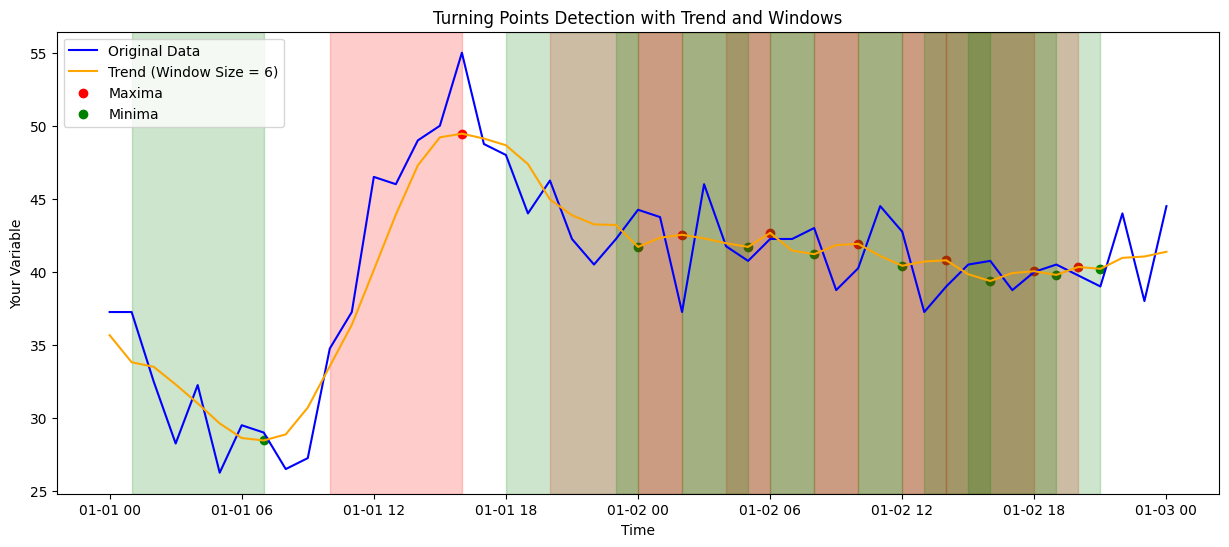

In [82]:
detect_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b055_raw', window_size = 6)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/1955705156.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:, 'date'] = df.index.date


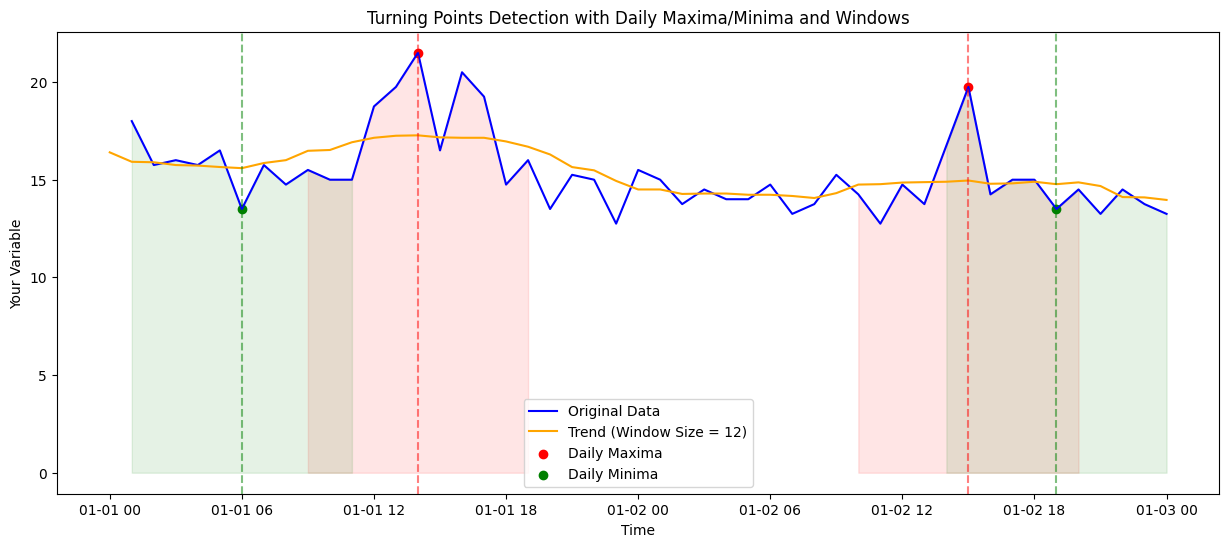

In [25]:
# Find max-min in one day

df1 = df1.set_index(pd.to_datetime(df1.index))

def detect_daily_turning_points(df, var, window_size=24):
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.index = pd.to_datetime(df.index)
    df.loc[:, 'date'] = df.index.date 
    
    grouped_maxima = df.iloc[local_maxima].groupby('date')[var].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')[var].idxmin().reset_index(drop=True)

    # grouped_maxima = df.iloc[local_maxima].groupby('date').apply(lambda x: x.loc[x[var].idxmax()])
    # grouped_minima = df.iloc[local_minima].groupby('date').apply(lambda x: x.loc[x[var].idxmin()])

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df[var], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')
    
    window_size_hours = 10  # 원하는 시간 간격을 설정하세요.
       # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=max_date, color='red', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                            color='red', alpha=0.1)

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=min_date, color='green', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                            color='green', alpha=0.1)
    """                          
   # 변곡점 구간 표시
    for date in grouped_maxima.index:
        max_date = pd.to_datetime(date)
        if max_date in df.index:
            plt.axvline(x = max_date, color = 'red', linestyle = '--', alpha = 0.5)
            window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
            window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
            plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                             color='red', alpha=0.1)

    for date in grouped_minima.index:
        min_date = pd.to_datetime(date)
        if min_date in df.index:
            plt.axvline(x = min_date, color = 'green', linestyle = '--', alpha = 0.5)
            window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
            window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
            plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                             color='green', alpha=0.1)
    
    """
    plt.scatter(grouped_maxima, df.loc[grouped_maxima, var], marker='o', color='red', label='Daily Maxima')
    plt.scatter(grouped_minima, df.loc[grouped_minima, var], marker='o', color='green', label='Daily Minima')

    plt.title('Turning Points Detection with Daily Maxima/Minima and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_daily_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b002_raw', window_size=12)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_41364/1955705156.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:, 'date'] = df.index.date


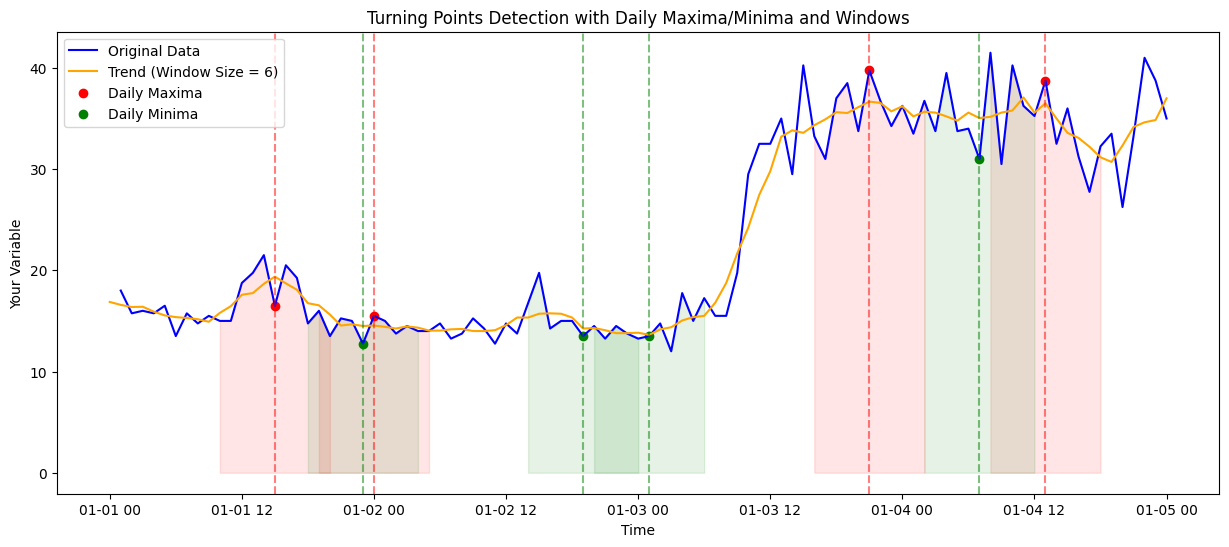

In [26]:
detect_daily_turning_points(df1["2020-01-01 00:00:00": "2020-01-05 00:00:00"], 'b002_raw', window_size=6)

In [ ]:
def detect_daily_turning_points(df, window_size=24, window_size_hours=6):
    # 시계열 분해 및 trend 추출
    trend = df['b002_raw'].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.loc[:, 'date'] = df.index.date  # Use .loc to create 'date' column

    grouped_maxima = df.iloc[local_maxima].groupby('date')['b002_raw'].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')['b002_raw'].idxmin().reset_index(drop=True)

    # 각 최댓값과 최솟값의 시간대 비교를 위한 리스트 초기화
    maxima_times = []
    minima_times = []

    # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        maxima_times.append(df[(df.index >= window_start) & (df.index <= window_end)]['b002_raw'].idxmax())

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        minima_times.append(df[(df.index >= window_start) & (df.index <= window_end)]['b002_raw'].idxmin())

    # 각 최댓값과 최솟값에 해당하는 시간대 출력
    print("Maxima Times:")
    print(df.loc[maxima_times, 'b002_raw'])

    print("\nMinima Times:")
    print(df.loc[minima_times, 'b002_raw'])

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df['b002_raw'], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')

    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours = window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours = window_size_hours / 2)
        plt.axvline(x = max_date, color = 'red', linestyle = '--', alpha = 0.5)
        plt.fill_between(df.index, 0, df['b002_raw'], where=(df.index >= window_start) & (df.index <= window_end),
                         color = 'red', alpha = 0.1)

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours = window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=min_date, color='green', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df['b002_raw'], where=(df.index >= window_start) & (df.index <= window_end),
                         color='green', alpha=0.1)

    plt.scatter(grouped_maxima, df.loc[grouped_maxima, 'b002_raw'], marker='o', color='red', label='Daily Maxima')
    plt.scatter(grouped_minima, df.loc[grouped_minima, 'b002_raw'], marker='o', color='green', label='Daily Minima')

    plt.title('Turning Points Detection with Daily Maxima/Minima and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_daily_turning_points(df1, window_size=24, window_size_hours=6)

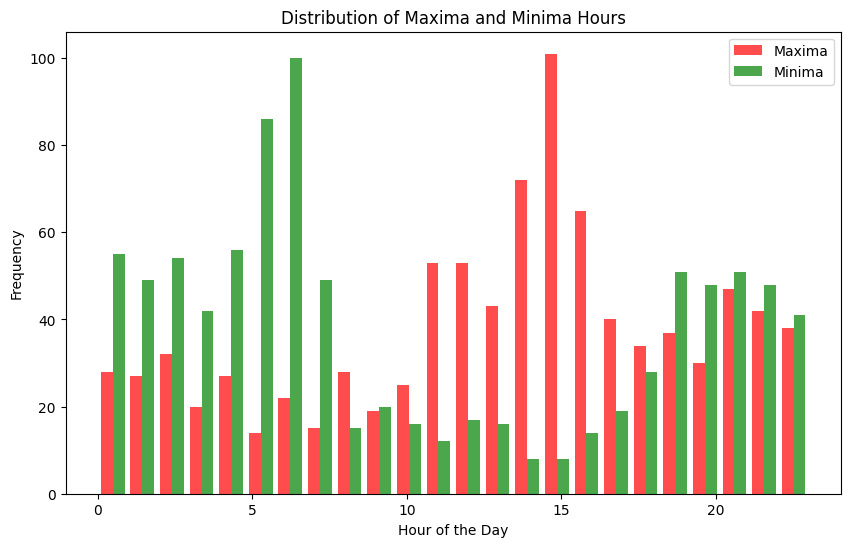

In [86]:
def detect_daily_turning_points(df, var, window_size=24, window_size_hours=6):
   
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.loc[:, 'date'] = df.index.date  # Use .loc to create 'date' column

    grouped_maxima = df.iloc[local_maxima].groupby('date')[var].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')[var].idxmin().reset_index(drop=True)

    # 각 최댓값과 최솟값의 시간대 비교를 위한 리스트 초기화
    maxima_times = []
    minima_times = []

    # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        maxima_times.append(df[(df.index >= window_start) & (df.index <= window_end)][var].idxmax())

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        minima_times.append(df[(df.index >= window_start) & (df.index <= window_end)][var].idxmin())

    # 각 최댓값과 최솟값에 해당하는 시간대를 추출
    maxima_hours = df.loc[maxima_times, var].index.hour
    minima_hours = df.loc[minima_times, var].index.hour

    # 그래프 표시
    plt.figure(figsize=(10, 6))
    plt.hist([maxima_hours, minima_hours], bins=24, alpha=0.7, color=['red', 'green'], label=['Maxima', 'Minima'])
    plt.title('Distribution of Maxima and Minima Hours')
    plt.xlabel('Hour of the Day')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_daily_turning_points(df1, 'b002_raw', window_size=24, window_size_hours=6)

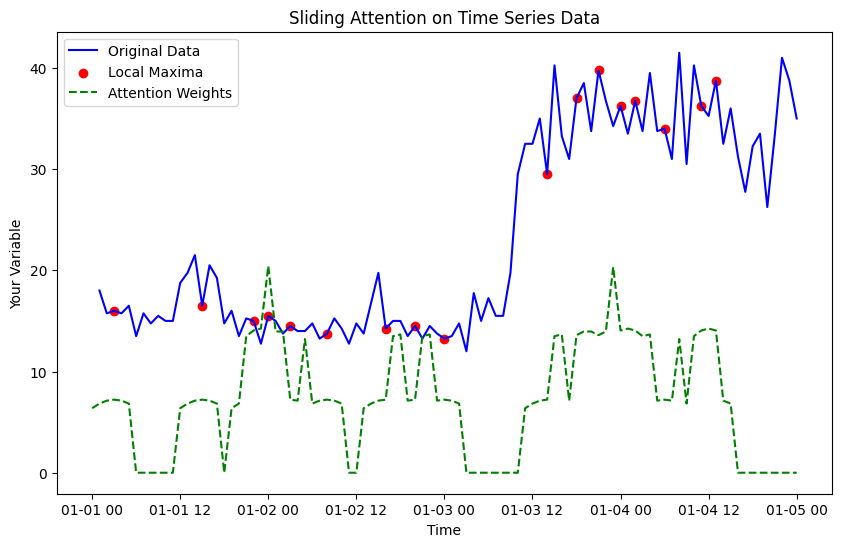

In [29]:
# apply attention for window

def sliding_attention(df, window_size=24, sigma=6):
    # 시계열 데이터에서의 변곡점 찾기
    trend = df['b002_raw'].rolling(window=window_size, min_periods=1, center=True).mean()
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    
    # Attention을 적용할 sliding window 설정
    attention_weights = np.zeros(len(df))
    
    for max_index in local_maxima:
        window_start = max(0, max_index - window_size//2)
        window_end = min(len(df), max_index + window_size//2)
        window_data = df['b002_raw'].iloc[window_start:window_end]
        
        # Gaussian 함수를 사용하여 각 데이터 포인트에 대한 가중치 계산
        weights = np.exp(-0.5 * ((np.arange(len(window_data)) - window_size//2) / sigma) ** 2)
        
        # Attention을 현재 sliding window에 적용
        attention_weights[window_start:window_end] += weights / np.sum(weights)
    
    # Attention이 적용된 데이터로 그래프 표시
    plt.figure(figsize=(10, 6))
    plt.plot(df.index, df['b002_raw'], label='Original Data', color='blue')
    plt.scatter(df.index[local_maxima], df['b002_raw'].iloc[local_maxima], color='red', marker='o', label='Local Maxima')
    plt.plot(df.index, attention_weights * df['b002_raw'].max(), label='Attention Weights', color='green', linestyle='--')
    
    plt.title('Sliding Attention on Time Series Data')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
sliding_attention(df1["2020-01-01 00:00:00": "2020-01-05 00:00:00"], window_size = 6, sigma=6)


In [ ]:
# Attention + LSTM-AE

def sliding_attention_lstm_ae(df, window_size=24, sigma=6, latent_dim=8):
    # 정규화
    scaler = MinMaxScaler()
    normalized_data = scaler.fit_transform(df[['your_variable']])
    
    # 시계열 데이터에서의 변곡점 찾기
    trend = df['your_variable'].rolling(window=window_size, min_periods=1, center=True).mean()
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    
    # Attention을 적용할 sliding window 설정
    attention_weights = np.zeros(len(df))
    
    for max_index in local_maxima:
        window_start = max(0, max_index - window_size//2)
        window_end = min(len(df), max_index + window_size//2)
        window_data = normalized_data[window_start:window_end]
        
        # Gaussian 함수를 사용하여 각 데이터 포인트에 대한 가중치 계산
        weights = np.exp(-0.5 * ((np.arange(len(window_data)) - window_size//2) / sigma) ** 2)
        
        # Attention을 현재 sliding window에 적용
        attention_weights[window_start:window_end] += weights / np.sum(weights)
    
    # LSTM-AE 모델 정의
    model = Sequential()
    model.add(LSTM(latent_dim, activation='relu', input_shape=(len(df), 1)))
    model.add(RepeatVector(len(df)))
    model.add(LSTM(1, activation='relu', return_sequences=True))
    model.add(TimeDistributed(Dense(1)))
    model.compile(optimizer='adam', loss='mse')

    # Attention Weights를 입력 데이터에 추가
    input_data = np.expand_dims(np.concatenate([normalized_data, np.expand_dims(attention_weights, axis=1)], axis=1), axis=0)

    # 모델 학습
    model.fit(input_data, input_data, epochs=50, batch_size=1, verbose=0)

    # 예측
    reconstructed_data = model.predict(input_data)

    # 시각화
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, scaler.inverse_transform(normalized_data)[:, 0], label='Original Data', color='blue')
    plt.plot(df.index, scaler.inverse_transform(reconstructed_data[0, :, :])[:, 0], label='Reconstructed Data', color='orange')
    plt.plot(df.index, attention_weights * df['your_variable'].max(), label='Attention Weights', color='green', linestyle='--')

    plt.title('Sliding Attention on LSTM-AE for Time Series Data')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
sliding_attention_lstm_ae(df1, window_size=24, sigma=6, latent_dim=8)
